# 📚 Import libraries

In [1]:
import hashlib
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from collections import defaultdict
import itertools
from threading import Thread
import os # For API keys
import warnings # To suppress warnings
import matplotlib.pyplot as plt
import spacy
from scipy.stats import norm


# 🗂️ Embedding model

## ⚙ Config

In [2]:
# --- Embedding Model Configuration ---
# Choose your embedding provider and model here
EMBEDDING_CONFIG = {
    # Options: "spacy", "sentence-transformers", "huggingface", "openai"
    "provider": "huggingface",
    #"provider": "sentence-transformers",

    # --- Provider Specific Settings ---
    # spacy: Model name (e.g., "en_core_web_sm", "en_core_web_md", "en_core_web_lg")
    "spacy_model_name": "en_core_web_sm",

    # sentence-transformers: Model name from Hugging Face Hub (e.g., "all-MiniLM-L6-v2", "multi-qa-mpnet-base-dot-v1")
    "st_model_name": "all-MiniLM-L6-v2",

    # huggingface: Model name from Hugging Face Hub (e.g., "bert-base-uncased", "roberta-base")
    "hf_model_name": "bert-base-uncased",
    "hf_pooling": "mean", # Options: "mean", "cls"

    # openai: Model name (e.g., "text-embedding-ada-002", "text-embedding-3-small")
    "openai_model_name": "text-embedding-ada-002",
}

# --- Global variables to hold loaded models (lazy loading) ---
_nlp = None
_st_model = None
_hf_tokenizer = None
_hf_model = None
_openai_client = None

# --- Model Loading and Embedding Function ---

def initialize_embedding_model():
    """Loads the embedding model based on EMBEDDING_CONFIG."""
    global _nlp, _st_model, _hf_tokenizer, _hf_model, _openai_client
    provider = EMBEDDING_CONFIG["provider"]

    if provider == "spacy":
        if _nlp is None:
            model_name = EMBEDDING_CONFIG["spacy_model_name"]
            try:
                _nlp = spacy.load(model_name)
                print(f"Loaded spaCy model: {model_name}")
            except OSError:
                print(f"SpaCy model '{model_name}' not found. Please install it: python -m spacy download {model_name}")
                raise
    elif provider == "sentence-transformers":
        if _st_model is None:
            try:
                from sentence_transformers import SentenceTransformer
                model_name = EMBEDDING_CONFIG["st_model_name"]
                _st_model = SentenceTransformer(model_name)
                print(f"Loaded Sentence Transformer model: {model_name}")
            except ImportError:
                print("Sentence Transformers library not found. Please install it: pip install sentence-transformers")
                raise
    elif provider == "huggingface":
        if _hf_model is None or _hf_tokenizer is None:
            try:
                # Suppress warnings about weights not being used for sequence classification
                warnings.filterwarnings("ignore", category=UserWarning, module='transformers.modeling_utils')
                from transformers import AutoTokenizer, AutoModel
                import torch
                warnings.filterwarnings("default", category=UserWarning, module='transformers.modeling_utils') # Reset warning

                model_name = EMBEDDING_CONFIG["hf_model_name"]
                _hf_tokenizer = AutoTokenizer.from_pretrained(model_name)
                _hf_model = AutoModel.from_pretrained(model_name)
                # Use GPU if available
                if torch.cuda.is_available():
                   _hf_model.to('cuda')
                print(f"Loaded Hugging Face model and tokenizer: {model_name}")
            except ImportError:
                print("Hugging Face Transformers library or PyTorch not found. Please install them: pip install transformers torch")
                raise
    elif provider == "openai":
        if _openai_client is None:
            try:
                from openai import OpenAI
                # Requires OPENAI_API_KEY environment variable to be set
                if not os.getenv("OPENAI_API_KEY"):
                    print("Warning: OPENAI_API_KEY environment variable not set for OpenAI embeddings.")
                    # Optionally raise an error here if you require OpenAI
                    # raise ValueError("OPENAI_API_KEY environment variable not set.")
                _openai_client = OpenAI() # Client automatically picks up the key from env var
                print(f"Initialized OpenAI client for model: {EMBEDDING_CONFIG['openai_model_name']}")
            except ImportError:
                print("OpenAI library not found. Please install it: pip install openai")
                raise
    else:
        raise ValueError(f"Unsupported embedding provider: {provider}")

## 🧰 Embedding tools

In [3]:
def get_embedding(text):
    """Generates an embedding for the given text using the configured model."""
    initialize_embedding_model() # Ensure model is loaded
    provider = EMBEDDING_CONFIG["provider"]

    if not text or not text.strip(): # Handle empty or whitespace-only strings
      warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")
      # Return a zero vector of the expected dimension. This is tricky without knowing the model first.
      # Let's try to get the dimension from the loaded model if possible, otherwise default.
      dim = 300 # Default fallback dimension
      if provider == "spacy" and _nlp and _nlp.vocab.vectors_length > 0:
          dim = _nlp.vocab.vectors_length
      elif provider == "sentence-transformers" and _st_model:
          dim = _st_model.get_sentence_embedding_dimension()
      elif provider == "huggingface" and _hf_model:
          dim = _hf_model.config.hidden_size
      elif provider == "openai":
           # OpenAI dims vary by model, ada-002 is 1536, text-embedding-3-small is 1536
           if EMBEDDING_CONFIG["openai_model_name"] in ["text-embedding-ada-002", "text-embedding-3-small"]:
               dim = 1536
           elif EMBEDDING_CONFIG["openai_model_name"] == "text-embedding-3-large":
               dim = 3072
           # Add other OpenAI models or a lookup mechanism if needed
      return np.zeros(dim)


    if provider == "spacy":
        doc = _nlp(text)
        return doc.vector
    elif provider == "sentence-transformers":
        # The encode function expects a list of sentences, but works fine with a single string too
        embedding = _st_model.encode(text)
        return embedding # Already a numpy array
    elif provider == "huggingface":
        import torch
        inputs = _hf_tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
        # Move inputs to GPU if model is on GPU
        if torch.cuda.is_available():
            inputs = {k: v.to('cuda') for k, v in inputs.items()}

        with torch.no_grad():
            outputs = _hf_model(**inputs)

        # Pooling strategy
        if EMBEDDING_CONFIG["hf_pooling"] == "mean":
            # Mean pooling: Average token embeddings, ignore padding
            attention_mask = inputs['attention_mask']
            mask_expanded = attention_mask.unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
            sum_embeddings = torch.sum(outputs.last_hidden_state * mask_expanded, 1)
            sum_mask = torch.clamp(mask_expanded.sum(1), min=1e-9)
            embedding = sum_embeddings / sum_mask
        elif EMBEDDING_CONFIG["hf_pooling"] == "cls":
            # CLS pooling: Use the embedding of the [CLS] token
            embedding = outputs.last_hidden_state[:, 0, :]
        else:
            raise ValueError(f"Unsupported Hugging Face pooling strategy: {EMBEDDING_CONFIG['hf_pooling']}")

        # Move embedding to CPU and convert to numpy
        return embedding.cpu().numpy().squeeze()

    elif provider == "openai":
        if not _openai_client:
             # Handle case where API key might be missing and client wasn't initialized
             print("Error: OpenAI client not available. Cannot get embedding.")
             # Return zero vector or raise error, similar to empty text handling
             # Using the dimension logic from above
             dim = 1536 # Default for common models
             if EMBEDDING_CONFIG["openai_model_name"] == "text-embedding-3-large":
                 dim = 3072
             return np.zeros(dim)

        response = _openai_client.embeddings.create(
            input=text,
            model=EMBEDDING_CONFIG["openai_model_name"]
        )
        return np.array(response.data[0].embedding)

    else:
        # Should have been caught by initialize_embedding_model, but just in case
        raise ValueError(f"Unsupported embedding provider: {provider}")


###
def calculate_distance(embedding1, embedding2):
    """Calculates the cosine distance between two embeddings."""
    # Ensure inputs are numpy arrays
    embedding1 = np.asarray(embedding1)
    embedding2 = np.asarray(embedding2)

    # Check for zero vectors
    norm1 = np.linalg.norm(embedding1)
    norm2 = np.linalg.norm(embedding2)
    if norm1 == 0 or norm2 == 0:
        if norm1 == 0 and norm2 == 0:
            return 0.0 # Distance between two zero vectors is 0
        else:
            return 1.0 # Distance between zero vector and non-zero vector is 1 (max cosine distance)

    # Reshape for cosine_similarity function (expects 2D arrays)
    if embedding1.ndim == 1:
        embedding1 = embedding1.reshape(1, -1)
    if embedding2.ndim == 1:
        embedding2 = embedding2.reshape(1, -1)

    # Calculate cosine similarity and convert to distance
    similarity = cosine_similarity(embedding1, embedding2)[0][0]
    # Clip similarity to [-1, 1] range due to potential floating point inaccuracies
    similarity = np.clip(similarity, -1.0, 1.0)
    return 1-similarity

# 📊 Plotting configs

In [4]:
# Default threshold configuration with multiple levels
THRESHOLD_CONFIG = {
    "context": {
        "method": "gaussian_average",  # Options: "gaussian_average", "custom", None
        "custom_value": 0.1,           # Value to use if method is "custom"
        "levels": [ 0.0,0.5, 0.75, 0.9],     # Standard deviations above the mean for levels
        "colors": ['lightcoral', 'salmon', 'red', "yellow"] # Corresponding colors for levels
    },
    "query": {
        "method": "gaussian_average",  # Options: "gaussian_average", "custom", None
        "custom_value": 0.1,           # Value to use if method is "custom"
        "levels": [0.0,0.5, 0.75],     # Standard deviations above the mean for levels
        "colors": ['lightblue', 'cornflowerblue', 'blue', 'black'] # Corresponding colors for levels
    },

}

COLORBLIND_COLORS = {
    'context_high': '#d73027',    # Strong red
    'context_medium': '#fc8d59',  # Orange
    'context_low': '#fee090',     # Light yellow/orange
    'query_high': '#4575b4',      # Strong blue
    'query_medium': '#74add1',    # Medium blue
    'query_low': '#abd9e9',       # Light blue
    'response': '#006400'         # Dark green
}

# 🧮 Define Classes & Functions

## 🧰 Classes

In [5]:
class RagThread(Thread):
    def __init__(self, group=None, target=None, name=None, args=(), kwargs={}, verbose=None):
        # Initializing the Thread class
        super().__init__(group, target, name, args, kwargs)
        self._return = None

    # Overriding the Thread.run function
    def run(self):
        if self._target is not None:
            self._return = self._target(*self._args, **self._kwargs)

    def join(self):
        super().join()
        return self._return

## ⚛ Functions

###  Tokenizer

---



In [6]:
# Load spaCy *only* for tokenization if not used for embeddings
_tokenizer_nlp = None
def get_tokenizer_nlp():
    """Loads a small spaCy model specifically for tokenization if needed."""
    global _tokenizer_nlp
    if _tokenizer_nlp is None:
        try:
            # Using small model just for tokenization is efficient
            _tokenizer_nlp = spacy.load("en_core_web_sm")
        except OSError:
            print("Default spaCy model 'en_core_web_sm' not found for tokenization. Please install it: python -m spacy download en_core_web_sm")
            # Fallback to basic split if spacy is unavailable
            print("Warning: Falling back to basic whitespace tokenization.")
            _tokenizer_nlp = 'fallback'
    return _tokenizer_nlp

def tokenize_and_filter(text):
    """Splits text into sentences instead of tokens."""
    tokenizer_nlp = get_tokenizer_nlp()

    if tokenizer_nlp == 'fallback':
        # Basic fallback if spaCy isn't available
        # Simple sentence splitting by punctuation and cleanup
        import re

        # Split on common sentence endings
        sentences = re.split(r'(?<=[.!?])\s+', text)

        # Remove empty sentences and strip whitespace
        sentences = [sentence.strip() for sentence in sentences if sentence.strip()]

        return sentences

    # Use spaCy for more robust sentence tokenization
    doc = tokenizer_nlp(text)
    sentences = [sent.text.strip() for sent in doc.sents if sent.text.strip()]

    return sentences

### Subtitutions

---



In [7]:
####
def remove_and_compute(sentences, original_response_embedding, category, sentence_impact_dict, chunk_embedding = None):
    """
    Computes the impact of removing each sentence.
    Uses hash of sentences as dictionary keys for consistent lookup.
    """
    impact_values = []
    new_sentence_impact_dict = defaultdict(list)
    distance_bw_chunk_and_response = 0
    if(chunk_embedding is not None):
          distance_bw_chunk_and_response = calculate_distance(chunk_embedding, original_response_embedding)
          print("distance chunk response", distance_bw_chunk_and_response, sentences)

    # Process each sentence
    for i, sentence_to_remove in enumerate(sentences):
        # Create a hash of the sentence for consistent key generation
        sentence_hash = hashlib.md5(sentence_to_remove.encode()).hexdigest()

        # Create text with the current sentence removed
        remaining_sentences = [s for j, s in enumerate(sentences) if i != j]
        remaining_text = " ".join(remaining_sentences)

        text_to_evaluate = ""
        if remaining_text.strip():
            text_to_evaluate = remaining_text

        text_to_evaluate_embedding = get_embedding(text_to_evaluate)


        distance_change = calculate_distance(text_to_evaluate_embedding, original_response_embedding)
        if(chunk_embedding is not None):
          distance_change = (distance_change - distance_bw_chunk_and_response)

        key = f"{category}_{sentence_hash}"
        if key in new_sentence_impact_dict:
            print("new distance", distance_change, remaining_sentences)
            new_sentence_impact_dict[key].append(distance_change)
        else:
            print("new distance", distance_change, remaining_sentences)

            new_sentence_impact_dict[key] = [distance_change]

        impact_values.append(distance_change)

    # Calculate mean impact across all sentences
    if impact_values:
        mean_impact = np.mean(impact_values)
        std_impact = np.std(impact_values) if np.std(impact_values) > 0 else 1

        max_impact = 1
        # Normalize the impacts relative to the mean
        for key, values in new_sentence_impact_dict.items():
            normalized_impact = (np.mean(values) - mean_impact) / (std_impact)
            if normalized_impact > max_impact:
                max_impact = normalized_impact
            if(key in sentence_impact_dict):
                sentence_impact_dict[key].append(normalized_impact)
            else:
                sentence_impact_dict[key] = [normalized_impact]

        for key, values in sentence_impact_dict.items():
            sentence_impact_dict[key] = [v / max_impact for v in values]  # Normalize by max impact (to make the range in -1, 1)

#####
def explain_by_token_removal(chunk, query, response):
    """
    Explains the influence of each token in the chunk and query
    by measuring the change in embedding distance of the response
    when each token is removed.
    """
    response_embedding = get_embedding(response) # Embedding of the actual RAG response
    chunk_embedding = get_embedding(chunk)
    query_embedding = get_embedding(query)

    chunk_sentences = tokenize_and_filter(chunk)
    query_sentences = tokenize_and_filter(query)

    token_impact = defaultdict(list)

    print("Analyzing chunk tokens wrt response...")
    remove_and_compute(chunk_sentences, response_embedding, "context", token_impact, chunk_embedding)

    print("Analyzing chunk tokens wrt query...")
    #remove_and_compute(chunk_sentences, query_embedding, "context", token_impact, chunk_embedding)

    print("Analyzing query tokens wrt response...")
    remove_and_compute(query_sentences, response_embedding, "query", token_impact, chunk_embedding)

    for key in  token_impact.keys():
        token_impact[key] = np.mean(token_impact[key])


    return token_impact



### Top-k explanations per sentece

---



In [8]:
#####
def rag_simulate(context, query):
    """
    A very basic simulation of a RAG system.
    In a real system, this would involve retrieving relevant parts of the context
    based on the query and then generating an answer.
    For this explainability task, we'll simply concatenate them (with a separator).
    This allows us to observe how changes in context/query affect the embedding
    of this "simulated" response.
    """
    return f"Context: {context} Query: {query}"


#####
def explain_by_sentence(chunk, response,k):
    """
    Explains the influence of each sentence in the chunk by measuring
    the change in embedding distance of the response when each sentence is removed.
    """
    chunk_sentences = tokenize_and_filter(chunk)
    response_sentences = tokenize_and_filter(response)

    sentence_impact = defaultdict(tuple)
    for response_sentence in response_sentences:
        sentence_hash = hashlib.md5(response_sentence.encode()).hexdigest()
        key = f"sentence_{sentence_hash}"
        response_sentence_embedding = get_embedding(response_sentence)

        for chunk_sentence in chunk_sentences:
            # Create a hash of the sentence for consistent key generation
            chunk_sentence_embedding = get_embedding(chunk_sentence)
            distance_change = calculate_distance(chunk_sentence_embedding, response_sentence_embedding)
            tuple_response_chunk = (chunk_sentence, distance_change)
            if key in sentence_impact :
                if len(sentence_impact[key]) < k:
                    sentence_impact[key].append(tuple_response_chunk)
                else:
                    for(s, d) in sentence_impact[key]:
                        if d > distance_change:
                            sentence_impact[key].remove((s, d))
                            sentence_impact[key].append(tuple_response_chunk)
                            break
            else:
                sentence_impact[key] = [tuple_response_chunk]
            sentence_impact[key] = sorted(sentence_impact[key], key=lambda x: x[1])# Keep only top k sentences

    return sentence_impact




### Utils

---



In [9]:
def explain_by_context_permutation(context, query, response, num_permutations=5):
    """
    Explains the influence of context syntactic formulation by measuring
    the change in embedding distance of the response for different
    permutations of the context sentences.
    """
    response_embedding = get_embedding(response) # Original response embedding
    context_hash = hashlib.md5(context.encode()).hexdigest() # Hash for consistent key generation

    # Use spaCy for sentence splitting
    tokenizer_nlp = get_tokenizer_nlp()
    if tokenizer_nlp == 'fallback':
        print("Warning: Cannot perform sentence permutation analysis without spaCy. Skipping.")
        return {}
    sentences = [sent.text.strip() for sent in tokenizer_nlp(context).sents if sent.text.strip()]

    if len(sentences) < 2:
        print("Context has less than 2 sentences. Skipping permutation analysis.")
        return {}

    permutation_impact = defaultdict(float)
    unique_permutations = set() # To avoid redundant permutations if num_permutations is large


    # Ensure the original order is considered if possible within the limit
    unique_permutations.add(context)

    all_perms = []
    for i in range(5):
        all_perms.append(np.random.permutation(sentences))
    np.random.shuffle(all_perms) # Shuffle to get varied permutations if num_permutations is smaller than total

    count = 0
    for perm_tuple in all_perms:
        permuted_context = " ".join(perm_tuple)
        if permuted_context not in unique_permutations:
            unique_permutations.add(permuted_context)
            count += 1
            if count >= num_permutations: # Stop after reaching the desired number *excluding* the original
                 break

    # If original wasn't added due to limit, remove one random to make space if needed
    if context not in unique_permutations and len(unique_permutations) >= num_permutations:
         unique_permutations.pop() # Remove a random element
         unique_permutations.add(context)


    print(f"Analyzing {len(unique_permutations)} context permutations (including original)...")
    for perm_context in unique_permutations:
        # Simulate RAG with the permuted context
        temp_simulated_response = rag_simulate(perm_context, query)
        temp_response_embedding = get_embedding(temp_simulated_response)

        # Compare the embedding of the *simulated response from permuted context*
        # to the embedding of the *original actual response*
        distance_change = calculate_distance(temp_response_embedding, response_embedding)
        permutation_hash = hashlib.md5(perm_context.encode()).hexdigest() # Hash for consistent key generation
        if permutation_hash == context_hash:
            permutation_impact["original"] = distance_change # Store distance, not change from original perm
        else:
            permutation_impact[perm_context] = distance_change # Store distance, not change from original perm

    return permutation_impact


def calculate_token_thresholds_with_levels(token_impact, threshold_config):
    """Calculates separate thresholds with multiple levels for context and query tokens."""
    context_impacts = [v for k, v in token_impact.items() if k.startswith("context_")]
    query_impacts = [v for k, v in token_impact.items() if k.startswith("query_")]
    thresholds = {}

    def get_thresholds_and_colors(impacts, config):
        method = config.get("method")
        levels = config.get("levels", [])
        colors = config.get("colors", [])
        threshold_colors = []
        if not impacts: # Handle cases with no tokens
            return [] # Return empty list if no impacts to calculate from

        # Ensure impacts are numbers
        impacts = [float(i) for i in impacts if isinstance(i, (int, float, np.number))]
        if not impacts: # Handle case where impacts were not numbers
             return []

        if method == "gaussian_average":
            avg = np.mean(impacts)
            std = np.std(impacts)
            # Ensure std is not zero or extremely small to avoid issues
            if std < 1e-9:
                std = 1e-9 # Use a small epsilon if std dev is effectively zero

            for i, level in enumerate(levels):
                threshold = avg + level
                print(f"Threshold {i}: {threshold:.8f} (Level: {level})")
                color = colors[i] if i < len(colors) else 'gray'
                threshold_colors.append((threshold, color))
            return sorted(threshold_colors) # Sort by threshold value ascending
        elif method == "custom":
            custom_value = config.get("custom_value", 0.0) # Default custom base to 0
            for i, level in enumerate(levels):
                # Assuming levels for custom are additive offsets from custom_value
                threshold = custom_value + level
                color = colors[i] if i < len(colors) else 'gray'
                threshold_colors.append((threshold, color))
            return sorted(threshold_colors) # Sort by threshold value ascending
        elif method is None:
             return [] # No thresholds calculated
        else:
            print(f"Warning: Unknown threshold method '{method}'. No thresholds calculated.")
            return []

    thresholds["context"] = get_thresholds_and_colors(context_impacts, threshold_config.get("context", {}))
    thresholds["query"] = get_thresholds_and_colors(query_impacts, threshold_config.get("query", {}))
    return thresholds


def calculate_fraction(value, impact_dict):
    if not impact_dict:
        return 0
    max_value = max(float(v) for v in impact_dict.values())
    max_value = max(max_value, 1)  # Avoid division by zero
    min_value = min(float(v) for v in impact_dict.values())
    min_value = min(min_value, -1)  # Avoid division by zero

    if max_value == 0:
        return 0
    return (float(value)-min_value) / (max_value- min_value)

def calculate_percentage(value, impact_dict):
    return calculate_fraction(value, impact_dict) * 100


def get_sentence_hash(sentence):
    return hashlib.md5(sentence.encode()).hexdigest()[:6]

def get_token_hash(token):
    return hashlib.md5(token.encode()).hexdigest()


### HTML rendering

---



# 📈 Analyze RAG

## 💟 Core function

Performs a complete RAG analysis and returns the results.

**Args**:

    context: The context text for RAG

    query: The query text
  
    response: The response generated by the RAG system
  
    analyze_permutations: Whether to analyze context permutations
  
    num_permutations: Number of permutations to analyze if enabled

**Returns**:

    Dictionary containing token_impact, permutation_impact, and thresholds
    

In [10]:
def analyze_rag(
    context,
    query,
    response,
    analyze_permutations=True,
    num_permutations=5
    ):

    print(f"--- Starting RAG Analysis ---")
    print(f"Embedding Provider: {EMBEDDING_CONFIG['provider']}")
    # Print specific model name based on provider
    provider = EMBEDDING_CONFIG['provider']
    model_key = f"{provider.split('-')[0]}_model_name" # e.g. spacy_model_name, st_model_name
    if model_key in EMBEDDING_CONFIG:
      print(f"Embedding Model: {EMBEDDING_CONFIG[model_key]}")
    elif provider == 'huggingface':
        print(f"Embedding Model: {EMBEDDING_CONFIG['hf_model_name']} (Pooling: {EMBEDDING_CONFIG['hf_pooling']})")


    # Initialize the model before analysis starts
    try:
        initialize_embedding_model()
    except Exception as e:
        print(f"Error initializing embedding model: {e}")
        # Return partial results or raise error
        return {
            "error": f"Failed to initialize embedding model: {e}",
            "token_impact": {},
            "permutation_impact": {},
            "thresholds": {},
            "context": context,
            "query": query,
            "response": response,
            "threshold_config": THRESHOLD_CONFIG,
            "embedding_config": EMBEDDING_CONFIG
        }

    token_impact = defaultdict(float)
    #multi-threading for each chunk of context which is an array of chunks
    threads = []
    for i, chunk in enumerate(context):
        print(f"Processing chunk {i+1}/{len(context)}: {chunk[:50]}...")
        thread = RagThread(target=explain_by_token_removal, args=(chunk, query, response))
        thread.start()
        threads.append(thread)

    for i in range(len(context)):
        test = threads[i].join()
        token_impact.update(test)

    # Analyze wich top k sentences in the context chunks
    sentence_impact = defaultdict(float)
    threads = []
    k = 4
    for i, chunk in enumerate(context):
        print(f"Processing chunk {i+1}/{len(context)}: {chunk[:50]}...")
        thread = RagThread(target=explain_by_sentence, args=(chunk, response,k))
        thread.start()
        threads.append(thread)


    for i in range(len(context)):
        test = threads[i].join()
        # results from each thread are merged into the main dictionary with the tuples updated depending on the distance values, every thread returns a dictionary which for each key has an array of tuples with the sentence and the distance value
        for key, value in test.items():
            if key in sentence_impact:
                sentence_impact[key].extend(value)
            else:
                sentence_impact[key] = value


    # sort the dictionary by distance value
    for key in sentence_impact.keys():
        sentence_impact[key] = sorted(sentence_impact[key], key=lambda x: x[1])[:k]



    # Analyze permutations if requested
    permutation_impact = {}
    if analyze_permutations:
        permutation_impact = explain_by_context_permutation(
            context, query, response, num_permutations=num_permutations
        )

    # Calculate thresholds
    thresholds = calculate_token_thresholds_with_levels(token_impact, THRESHOLD_CONFIG)
    print(f"--- Analysis Complete ---")

    return {
        "token_impact": token_impact,
        "permutation_impact": permutation_impact,
        "sentence_impact": sentence_impact,
        "thresholds": thresholds,
        "context": context,
        "query": query,
        "response": response,
        "threshold_config": THRESHOLD_CONFIG,
        "embedding_config": EMBEDDING_CONFIG # Include embedding config in results
    }

## 🔤 Define context/chunks -  query - response

In [11]:
context = [
        "Lionel Messi won the Ballon d'Or in 2023, his eighth time receiving the award. He played a crucial role in Argentina’s World Cup win in 2022.",
        "Cristiano Ronaldo has scored over 800 career goals and currently plays in the Saudi Pro League. He is also a five-time Ballon d'Or winner.",
        "Erling Haaland had a record-breaking season in 2023 with Manchester City, scoring 52 goals across all competitions and winning the treble.",
        "Football is the most popular sport in the world. It is played in over 200 countries and followed by billions of fans."
        ]
#query = "What were the main causes of the global supply chain crisis during the COVID-19 pandemic, and how did companies adapt to these disruptions?"
query= "Who is the best football player in the world?"
#response = "The global supply chain crisis during COVID-19 was driven by factory shutdowns, shipping disruptions, and mismatches in supply and demand. Companies adapted by adopting more resilient inventory strategies and accelerating digital transformation. Labor shortages due to quarantine also worsened the situation."
response = "Many fans consider Lionel Messi to be the best football player in the world, especially after winning his eighth Ballon d'Or and leading Argentina to a World Cup title in 2022. Others may argue for Cristiano Ronaldo or Erling Haaland based on their recent performances."

# 🟥 Main

## Analysis

---



In [18]:
# Run analysis
print("Running RAG explainability analysis...")
analysis_results = analyze_rag(
    context, query, response,
    analyze_permutations=False,
    num_permutations=4
)



print("\nToken Impact:")
for token, impact in sorted(analysis_results["token_impact"].items(), key=lambda item: item[1], reverse=True):
    print(f"{token}: {impact:.4f}")



Running RAG explainability analysis...
--- Starting RAG Analysis ---
Embedding Provider: huggingface
Embedding Model: bert-base-uncased (Pooling: mean)
Processing chunk 1/4: Lionel Messi won the Ballon d'Or in 2023, his eigh...
Processing chunk 2/4: Cristiano Ronaldo has scored over 800 career goals...
Processing chunk 3/4: Erling Haaland had a record-breaking season in 202...
Processing chunk 4/4: Football is the most popular sport in the world. I...
Analyzing chunk tokens wrt response...
distance chunk response 0.2627784 ['Football is the most popular sport in the world.', 'It is played in over 200 countries and followed by billions of fans.']
Analyzing chunk tokens wrt response...
distance chunk response 0.17610317 ['Erling Haaland had a record-breaking season in 2023 with Manchester City, scoring 52 goals across all competitions and winning the treble.']
new distance 0.8238968 []
Analyzing chunk tokens wrt query...
Analyzing query tokens wrt response...
distance chunk response 0.17

<ipython-input-3-acf1c2259adb>:7: UserWarning: Attempting to get embedding for empty or whitespace-only text. Returning zero vector.
  warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")
<ipython-input-3-acf1c2259adb>:7: UserWarning: Attempting to get embedding for empty or whitespace-only text. Returning zero vector.
  warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")


new distance 0.13952333 ['It is played in over 200 countries and followed by billions of fans.']
new distance 0.22996235 ["He is also a five-time Ballon d'Or winner."]
new distance 0.1265024 ['He played a crucial role in Argentina’s World Cup win in 2022.']
new distance 0.046418548 ['Football is the most popular sport in the world.']
Analyzing chunk tokens wrt query...
Analyzing query tokens wrt response...
distance chunk response 0.2627784 ['Who is the best football player in the world?']
new distance 0.7372216 []


<ipython-input-3-acf1c2259adb>:7: UserWarning: Attempting to get embedding for empty or whitespace-only text. Returning zero vector.
  warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")
<ipython-input-3-acf1c2259adb>:7: UserWarning: Attempting to get embedding for empty or whitespace-only text. Returning zero vector.
  warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")
<ipython-input-3-acf1c2259adb>:7: UserWarning: Attempting to get embedding for empty or whitespace-only text. Returning zero vector.
  warnings.warn("Attempting to get embedding for empty or whitespace-only text. Returning zero vector.")


new distance 0.044297278 ['Cristiano Ronaldo has scored over 800 career goals and currently plays in the Saudi Pro League.']
Analyzing chunk tokens wrt query...
Analyzing query tokens wrt response...
distance chunk response 0.1259132 ['Who is the best football player in the world?']
new distance 0.8740868 []
new distance 0.088496566 ["Lionel Messi won the Ballon d'Or in 2023, his eighth time receiving the award."]
Analyzing chunk tokens wrt query...
Analyzing query tokens wrt response...
distance chunk response 0.097640395 ['Who is the best football player in the world?']
new distance 0.9023596 []
Processing chunk 1/4: Lionel Messi won the Ballon d'Or in 2023, his eigh...
Processing chunk 2/4: Cristiano Ronaldo has scored over 800 career goals...
Processing chunk 3/4: Erling Haaland had a record-breaking season in 202...
Processing chunk 4/4: Football is the most popular sport in the world. I...
Threshold 0: 0.00000000 (Level: 0.0)
Threshold 1: 0.50000000 (Level: 0.5)
Threshold 2: 0.75

## Analize permutations

---



In [13]:
# Print permutation results if available
if analysis_results["permutation_impact"]:
    print("\nContext Permutation Impact:")
    for perm, impact in sorted(analysis_results["permutation_impact"].items(), key=lambda item: item[1], reverse=True):
        print(f"{impact:.4f}: {perm[:50]}...")  # Print first 50 chars


# Visualize results

In [14]:
context = analysis_results.get("context", "")
query = analysis_results.get("query", "")
response = analysis_results.get("response", "")
token_impact = analysis_results.get("token_impact", {})
pseudo_response = analysis_results.get("pseudo_response", "")
threshold_config = analysis_results.get("threshold_config", {})
thresholds = analysis_results.get("thresholds", {})

print(f"Context: {context}")
print(f"Query: {query}")
print(f"Response: {response}")
print(f"Token Impact: {token_impact}")
print(f"Pseudo Response: {pseudo_response}")
print(f"Threshold Config: {threshold_config}")
print(f"Thresholds: {thresholds}")


Context: ["Lionel Messi won the Ballon d'Or in 2023, his eighth time receiving the award. He played a crucial role in Argentina’s World Cup win in 2022.", "Cristiano Ronaldo has scored over 800 career goals and currently plays in the Saudi Pro League. He is also a five-time Ballon d'Or winner.", 'Erling Haaland had a record-breaking season in 2023 with Manchester City, scoring 52 goals across all competitions and winning the treble.', 'Football is the most popular sport in the world. It is played in over 200 countries and followed by billions of fans.']
Query: Who is the best football player in the world?
Response: Many fans consider Lionel Messi to be the best football player in the world, especially after winning his eighth Ballon d'Or and leading Argentina to a World Cup title in 2022. Others may argue for Cristiano Ronaldo or Erling Haaland based on their recent performances.
Token Impact: defaultdict(<class 'float'>, {'context_290b8d5f8565ff64228b686f0350a1ef': np.float32(1.0), 'c

## HTML render

---



#### Function

In [15]:
nlp = spacy.load("en_core_web_sm")

def visualize_results_html(analysis_results):
    """
    Generates an elegant HTML visualization of the token and permutation impact,
    with a modern, clean design and interactive elements.

    Args:
        analysis_results: Dictionary with analysis results from analyze_rag()

    Returns:
        HTML string representation of the analysis
    """
    token_impact = analysis_results["token_impact"]
    sentence_impact = analysis_results["sentence_impact"]
    context = analysis_results["context"]
    query = analysis_results["query"]
    response = analysis_results["response"]
    thresholds = analysis_results["thresholds"]

    context_impacts = {k: v for k, v in token_impact.items() if k.startswith("context_")}
    permutation_impact = analysis_results.get("permutation_impact", {})

    # Helper function to get appropriate color for a value based on thresholds
    def get_color_for_value(value, threshold_list):
        for threshold, color in sorted(threshold_list, key=lambda x: x[0], reverse=True):
            if value >= threshold:
                return color
        return "transparent"  # Default transparent background if below all thresholds

    # Helper function to calculate percentage impact based on max and min values

    context_html = []
    chunk_count = 0

    for chunk in context:
        chunk_count += 1
        context_sentences = tokenize_and_filter(chunk)
        context_html.append(f"<div class='chunk-header'>Chunk {chunk_count}</div>")

        chunk_content = []
        for sentence in context_sentences:
            token_hash = "context_"+hashlib.md5(sentence.encode()).hexdigest()

            if token_hash in context_impacts.keys():
                impact_value = context_impacts[token_hash]
                color = get_color_for_value(impact_value, thresholds["context"])
                percentage = calculate_percentage(impact_value, context_impacts)

                # Calculate opacity for visual indication of impact
                opacity = min(0.9, max(0.15, percentage/100))

                # Create span with tooltip showing impact percentage
                span = f'<span class="highlight" style="background-color: {color}; opacity: {opacity};" data-impact="{percentage:.2f}%">{sentence}</span>'
                chunk_content.append(span)
            else:
                # If token not found in context impacts, add it without highlighting
                chunk_content.append(f'<span>{sentence}</span>')

        context_html.append("<div class='chunk-content'>" + "".join(chunk_content) + "</div>")

    # Process query highlighting with improved visualization
    query_sentences = tokenize_and_filter(query)
    query_impacts = {k: v for k, v in token_impact.items() if k.startswith("query_")}
    query_html = []

    # Map hashes for query tokens
    for token in query_sentences:
        token_hash = "query_" + hashlib.md5(token.encode()).hexdigest()
        if token_hash in query_impacts.keys():
            impact_value = query_impacts[token_hash]
            color = get_color_for_value(impact_value, thresholds["query"])
            percentage = calculate_percentage(impact_value, query_impacts)

            # Calculate opacity for visual indication of impact
            opacity = min(0.9, max(0.15, percentage/100))

            # Create span with tooltip showing impact percentage
            span = f'<span class="highlight" style="background-color: {color}; {"color:white;" if color== "blue" else ""} opacity: {opacity};" data-impact="{percentage:.2f}%">{token}</span>'
            query_html.append(span)
        else:
            # If token not found in query impacts, add it without highlighting
            query_html.append(token)

    # Process response sentences and their relationship to context
    response_sentences = tokenize_and_filter(response)
    response_sentence_impacts = {k: v for k, v in sentence_impact.items() if k.startswith("sentence_")}

    response_html = "<div class='response-analysis'>"
    response_html += "<h3>Response Sentence Analysis</h3>"
    response_html += "<div class='sentence-cards'>"

    for sentence in response_sentences:
        sentence_hash = "sentence_" + hashlib.md5(sentence.encode()).hexdigest()
        if sentence_hash in response_sentence_impacts.keys():
            impact_value_tuples = response_sentence_impacts[sentence_hash]
            impact_value_tuples = sorted(impact_value_tuples, key=lambda x: float(x[1]))

            # Create a card for each response sentence
            response_html += """
            <div class='sentence-card'>
                <div class='response-sentence'>
                    <svg class="quote-icon" viewBox="0 0 24 24" width="20" height="20">
                        <path d="M14,17H17L19,13V7H13V13H16M6,17H9L11,13V7H5V13H8L6,17Z" />
                    </svg>
                    <span>""" + sentence + """</span>
                </div>
                <div class='similar-contexts'>
                    <h4>Most similar context sentences</h4>
                    <ul>
            """

            # Add each related context sentence with a similarity score
            for idx, (context_sentence, impact_value) in enumerate(impact_value_tuples):
                # Create a visual indicator of similarity strength
                similarity_percentage = min(100, max(0, float(impact_value) * 100))
                # Color gradient: green (high) to amber (medium) to red (low)
                hue = min(120, max(0, similarity_percentage * 1.2))
                progress_color = f"hsl({hue}, 80%, 45%)"

                response_html += f"""
                    <li class="{'primary' if idx == 0 else ''}">
                        <div class='context-sentence'>
                            {context_sentence}
                        </div>
                        <div class='similarity-container'>
                            <div class='similarity-score'>Similarity: <strong>{float(impact_value):.3f}</strong></div>
                            <div class='similarity-bar-container'>
                                <div class='similarity-bar' style='width: {similarity_percentage}%; background-color: {progress_color};'></div>
                            </div>
                        </div>
                    </li>
                """

            response_html += """
                    </ul>
                </div>
            </div>
            """

    response_html += "</div></div>"

    # Format permutation impact information with improved visualization
    permutation_html = ""
    if permutation_impact:
        permutation_html = "<div class='permutation-section'>"
        permutation_html += "<h3>Permutation Impact Analysis</h3>"

        # Extract original value for comparison
        max_perm = permutation_impact["original"]

        # Create a table for permutation impacts
        permutation_html += """
        <table class="permutation-table">
            <thead>
                <tr>
                    <th>Permutation</th>
                    <th>Impact</th>
                    <th>Change</th>
                    <th>Visualization</th>
                </tr>
            </thead>
            <tbody>
        """

        # Add row for original arrangement
        permutation_html += f"""
            <tr class="original-row">
                <td>Original</td>
                <td>{float(max_perm):.4f}</td>
                <td>Baseline</td>
                <td>
                    <div class="permutation-bar-container">
                        <div class="permutation-bar baseline" style="width: 100%"></div>
                    </div>
                </td>
            </tr>
        """

        # Sort permutations by impact
        sorted_perms = sorted(
            [(k, v) for k, v in permutation_impact.items() if k != "original"],
            key=lambda x: float(x[1])
        )

        for perm, impact in sorted_perms:
            percentage_change = (float(impact) / max_perm) * 100 - 100
            is_improvement = percentage_change > 0

            # Calculate width based on relative impact
            bar_width = min(100, max(5, (float(impact) / max_perm) * 100))

            # Determine color based on improvement or decline
            bar_color = "var(--color-success)" if is_improvement else "var(--color-error)"

            permutation_html += f"""
                <tr>
                    <td>{perm}</td>
                    <td>{float(impact):.4f}</td>
                    <td class="{'' if is_improvement else 'negative'}">
                        <svg class="trend-icon" viewBox="0 0 24 24" width="16" height="16">
                            <path d="{'M16,6L12,2L8,6H11V13H13V6H16M8,18L12,22L16,18H13V11H11V18H8Z' if is_improvement else 'M16,18L12,22L8,18H11V11H13V18H16M8,6L12,2L16,6H13V13H11V6H8Z'}" />
                        </svg>
                        {abs(percentage_change):.2f}%
                    </td>
                    <td>
                        <div class="permutation-bar-container">
                            <div class="permutation-bar" style="width: {bar_width}%; background-color: {bar_color}"></div>
                        </div>
                    </td>
                </tr>
            """

        permutation_html += """
            </tbody>
        </table>
        </div>
        """

    # Create elegant legend with visual indicators
    context_legend = """
    <div class="legend-header">Context Impact</div>
    <div class="color-scale">
    """

    # Sort threshold colors from highest to lowest
    sorted_thresholds = sorted(thresholds["context"], key=lambda x: x[0], reverse=True)

    # Generate color scale stops
    for i, (threshold, color) in enumerate(sorted_thresholds):
        percentage = calculate_percentage(threshold, context_impacts)
        context_legend += f"""
        <div class="color-stop">
            <div class="color-sample" style="background-color: {color}"></div>
            <div class="threshold-value">{float(percentage):.1f}%+</div>
        </div>
        """

    context_legend += """
    </div>
    """

    query_legend = """
    <div class="legend-header">Query Impact</div>
    <div class="color-scale">
    """

    # Sort threshold colors from highest to lowest
    sorted_thresholds = sorted(thresholds["query"], key=lambda x: x[0], reverse=True)

    # Generate color scale stops
    for threshold, color in sorted_thresholds:
        percentage = calculate_percentage(threshold, query_impacts)
        query_legend += f"""
        <div class="color-stop">
            <div class="color-sample" style="background-color: {color}"></div>
            <div class="threshold-value">{float(percentage):.1f}%+</div>
        </div>
        """

    query_legend += """
    </div>
    """

    # Include JavaScript for interactive features
    javascript = """
    <script>
    document.addEventListener('DOMContentLoaded', function() {
        // Add hover tooltips to highlighted spans
        const highlights = document.querySelectorAll('.highlight');
        highlights.forEach(span => {
            span.addEventListener('mouseenter', function(e) {
                const impact = this.getAttribute('data-impact');

                // Create tooltip
                const tooltip = document.createElement('div');
                tooltip.className = 'tooltip';
                tooltip.textContent = `Impact: ${impact}`;

                // Position tooltip
                const rect = this.getBoundingClientRect();
                tooltip.style.left = `${rect.left + window.scrollX}px`;
                tooltip.style.top = `${rect.top + window.scrollY - 30}px`;

                // Add to DOM
                document.body.appendChild(tooltip);

                // Store reference
                this.tooltip = tooltip;
            });

            span.addEventListener('mouseleave', function() {
                if (this.tooltip) {
                    this.tooltip.remove();
                    this.tooltip = null;
                }
            });
        });

        // Add toggle functionality for sentence cards
        const sentenceCards = document.querySelectorAll('.sentence-card');
        sentenceCards.forEach(card => {
            card.addEventListener('click', function() {
                this.classList.toggle('expanded');
            });
        });
    });
    </script>
    """

    # Build the complete HTML with elegant styling
    html = f"""
    <!DOCTYPE html>
    <html lang="en">
    <head>
        <meta charset="UTF-8">
        <meta name="viewport" content="width=device-width, initial-scale=1.0">
        <title>RAG Analysis Visualization</title>
        <style>
            :root {{
                --color-primary: #3a86ff;
                --color-primary-light: #60a5fa;
                --color-primary-dark: #1e40af;
                --color-secondary: #4b5563;
                --color-accent: #8b5cf6;
                --color-success: #10b981;
                --color-warning: #f59e0b;
                --color-error: #ef4444;
                --color-text: #1f2937;
                --color-text-light: #6b7280;
                --color-text-lightest: #9ca3af;
                --color-background: #f9fafb;
                --color-card: #ffffff;
                --color-border: #e5e7eb;
                --color-highlight: #fef3c7;
                --shadow-sm: 0 1px 2px 0 rgba(0, 0, 0, 0.05);
                --shadow: 0 1px 3px 0 rgba(0, 0, 0, 0.1), 0 1px 2px 0 rgba(0, 0, 0, 0.06);
                --shadow-md: 0 4px 6px -1px rgba(0, 0, 0, 0.1), 0 2px 4px -1px rgba(0, 0, 0, 0.06);
                --shadow-lg: 0 10px 15px -3px rgba(0, 0, 0, 0.1), 0 4px 6px -2px rgba(0, 0, 0, 0.05);
                --rounded-sm: 4px;
                --rounded: 8px;
                --rounded-md: 12px;
                --rounded-lg: 16px;
                --transition: all 0.3s ease;
                --font-sans: 'Inter', -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial, sans-serif;
                --font-mono: 'Roboto Mono', 'SFMono-Regular', Consolas, 'Liberation Mono', Menlo, monospace;
            }}

            * {{
                box-sizing: border-box;
                margin: 0;
                padding: 0;
            }}

            body {{
                font-family: var(--font-sans);
                font-size: 16px;
                line-height: 1.5;
                color: var(--color-text);
                background-color: var(--color-background);
                padding: 2rem;
            }}

            .container {{
                max-width: 1200px;
                margin: 0 auto;
            }}

            /* Typography */
            h1, h2, h3, h4, h5, h6 {{
                margin: 0;
                line-height: 1.2;
                font-weight: 600;
                color: var(--color-text);
            }}

            h1 {{
                font-size: 2.5rem;
                font-weight: 700;
                margin-bottom: 2rem;
                color: var(--color-primary-dark);
                position: relative;
                display: inline-block;
            }}

            h1::after {{
                content: '';
                position: absolute;
                bottom: -10px;
                left: 0;
                width: 60px;
                height: 4px;
                background-color: var(--color-primary);
                border-radius: 2px;
            }}

            h2 {{
                font-size: 1.5rem;
                margin-bottom: 1rem;
                color: var(--color-primary-dark);
            }}

            h3 {{
                font-size: 1.25rem;
                margin-bottom: 1rem;
                color: var(--color-primary);
            }}

            h4 {{
                font-size: 1rem;
                color: var(--color-secondary);
                margin-bottom: 0.5rem;
            }}

            p {{
                margin-bottom: 1rem;
            }}

            /* Card Layouts */
            .section-card {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
                transition: var(--transition);
            }}

            .section-card:hover {{
                box-shadow: var(--shadow-md);
            }}

            /* Legend */
            .legend-container {{
                display: flex;
                justify-content: space-between;
                gap: 1.5rem;
                margin-bottom: 2rem;
                flex-wrap: wrap;
            }}

            .legend {{
                flex: 1;
                min-width: 200px;
                background-color: var(--color-card);
                padding: 1.25rem;
                border-radius: var(--rounded);
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
            }}

            .legend-header {{
                font-weight: 600;
                margin-bottom: 1rem;
                color: var(--color-primary-dark);
                font-size: 1rem;
            }}

            .color-scale {{
                display: flex;
                flex-direction: column;
                gap: 0.75rem;
            }}

            .color-stop {{
                display: flex;
                align-items: center;
                gap: 0.5rem;
            }}

            .color-sample {{
                width: 20px;
                height: 20px;
                border-radius: var(--rounded-sm);
                border: 1px solid rgba(0,0,0,0.1);
            }}

            .threshold-value {{
                font-size: 0.875rem;
                color: var(--color-text-light);
            }}

            /* Query Section */
            .query-section {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
                position: relative;
                overflow: hidden;
            }}

            .query-section::before {{
                content: 'Query';
                position: absolute;
                top: 0;
                right: 0;
                background-color: var(--color-primary);
                color: white;
                font-size: 0.75rem;
                font-weight: 600;
                padding: 0.25rem 0.75rem;
                border-bottom-left-radius: var(--rounded-sm);
                text-transform: uppercase;
                letter-spacing: 0.05em;
            }}

            /* Context Section */
            .context-section {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
                position: relative;
                overflow: hidden;
            }}

            .context-section::before {{
                content: 'Context';
                position: absolute;
                top: 0;
                right: 0;
                background-color: var(--color-secondary);
                color: white;
                font-size: 0.75rem;
                font-weight: 600;
                padding: 0.25rem 0.75rem;
                border-bottom-left-radius: var(--rounded-sm);
                text-transform: uppercase;
                letter-spacing: 0.05em;
            }}

            .chunk-header {{
                font-weight: 600;
                margin-top: 1.25rem;
                margin-bottom: 0.5rem;
                padding-bottom: 0.5rem;
                border-bottom: 1px solid var(--color-border);
                color: var(--color-secondary);
                font-size: 0.9rem;
            }}

            .chunk-content {{
                line-height: 1.6;
                margin-bottom: 1rem;
            }}

            .highlight {{
                border-radius: 3px;
                transition: all 0.2s ease;
                cursor: pointer;
                padding: 2px 0;
                position: relative;
            }}

            .highlight:hover {{
                opacity: 0.8 !important;
            }}

            .tooltip {{
                position: absolute;
                background-color: rgba(0, 0, 0, 0.8);
                color: white;
                padding: 4px 8px;
                border-radius: 4px;
                font-size: 12px;
                pointer-events: none;
                z-index: 100;
                white-space: nowrap;
            }}

            /* Response Section */
            .response-section {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
                position: relative;
                overflow: hidden;
            }}

            .response-section::before {{
                content: 'Response';
                position: absolute;
                top: 0;
                right: 0;
                background-color: var(--color-accent);
                color: white;
                font-size: 0.75rem;
                font-weight: 600;
                padding: 0.25rem 0.75rem;
                border-bottom-left-radius: var(--rounded-sm);
                text-transform: uppercase;
                letter-spacing: 0.05em;
            }}

            /* Response Analysis */
            .response-analysis {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
            }}

            .sentence-cards {{
                display: grid;
                grid-template-columns: repeat(auto-fill, minmax(400px, 1fr));
                gap: 1.5rem;
                margin-top: 1.5rem;
            }}

            .sentence-card {{
                background-color: white;
                border-radius: var(--rounded);
                box-shadow: var(--shadow);
                overflow: hidden;
                border: 1px solid var(--color-border);
                transition: var(--transition);
                cursor: pointer;
            }}

            .sentence-card:hover {{
                transform: translateY(-4px);
                box-shadow: var(--shadow-md);
            }}

            .response-sentence {{
                padding: 1.25rem;
                background-color: #f0f7ff;
                border-left: 4px solid var(--color-primary);
                font-size: 1rem;
                font-weight: 500;
                color: var(--color-text);
                position: relative;
                display: flex;
                align-items: flex-start;
                gap: 0.5rem;
            }}

            .quote-icon {{
                fill: var(--color-primary);
                flex-shrink: 0;
                margin-top: 3px;
            }}

            .similar-contexts {{
                padding: 1.25rem;
            }}

            .similar-contexts h4 {{
                margin-top: 0;
                margin-bottom: 1rem;
                font-size: 0.9rem;
                color: var(--color-text-light);
                font-weight: 500;
            }}

            .similar-contexts ul {{
                list-style-type: none;
                padding: 0;
                margin: 0;
            }}

            .similar-contexts li {{
                padding: 0.75rem 0;
                border-bottom: 1px solid var(--color-border);
            }}

            .similar-contexts li.primary {{
                background-color: #fcfcfc;
            }}

            .similar-contexts li:last-child {{
                border-bottom: none;
            }}

            .context-sentence {{
                margin-bottom: 0.5rem;
                font-size: 0.9rem;
                color: var(--color-text);
                display: flex;
                align-items: flex-start;
                gap: 0.5rem;
            }}

            .link-icon {{
                fill: var(--color-text-lightest);
                flex-shrink: 0;
                margin-top: 3px;
            }}

            .similarity-container {{
                display: flex;
                align-items: center;
                margin-top: 0.5rem;
                gap: 1rem;
            }}

            .similarity-score {{
                font-size: 0.8rem;
                color: var(--color-text-light);
                white-space: nowrap;
            }}

            .similarity-score strong {{
                color: var(--color-text);
            }}

            .similarity-bar-container {{
                flex-grow: 1;
                height: 6px;
                background-color: #eee;
                border-radius: 3px;
                overflow: hidden;
            }}

            .similarity-bar {{
                height: 100%;
                border-radius: 3px;
                transition: width 0.3s ease;
            }}

            /* Permutation Section */
            .permutation-section {{
                background-color: var(--color-card);
                border-radius: var(--rounded-md);
                padding: 1.5rem;
                margin-bottom: 2rem;
                box-shadow: var(--shadow);
                border: 1px solid var(--color-border);
            }}

            .permutation-table {{
                width: 100%;
                border-collapse: collapse;
                margin-top: 1rem;
                font-size: 0.9rem;
            }}

            .permutation-table th,
            .permutation-table td {{
                padding: 0.75rem 1rem;
                text-align: left;
                border-bottom: 1px solid var(--color-border);
            }}

            .permutation-table th {{
                font-weight: 600;
                color: var(--color-text);
                background-color: #f9fafb;
            }}

            .permutation-table tbody tr:hover {{
                background-color: #f9fafb;
            }}

            .permutation-table .original-row {{
                background-color: #f0f7ff;
            }}

            .permutation-bar-container {{
                width: 100%;
                height: 8px;
                background-color: #eee;
                border-radius: 4px;
                overflow: hidden;
            }}

            .permutation-bar {{
                height: 100%;
                border-radius: 4px;
                transition: width 0.3s ease;
            }}

            .permutation-bar.baseline {{
                background-color: var(--color-primary);
            }}

            .trend-icon {{
                vertical-align: middle;
                margin-right: 4px;
                fill: currentColor;
            }}

            .negative {{
                color: var(--color-error);
            }}

            /* Responsive Adjustments */
            @media (max-width: 768px) {{
                body {{
                    padding: 1rem;
                }}

                .sentence-cards {{
                    grid-template-columns: 1fr;
                }}
            }}
        </style>
        {javascript}
    </head>
    <body>
        <div class="container">
            <h1>RAG Analysis Visualization</h1>

            <div class="legend-container">
                <div class="legend">
                    {context_legend}
                </div>
                <div class="legend">
                    {query_legend}
                </div>
            </div>

            <div class="query-section">
                <h2>Query</h2>
                <p>{"".join(query_html)}</p>
            </div>

            <div class="context-section">
                <h2>Context</h2>
                <p>{"".join(context_html)}</p>
            </div>

            <div class="response-section">
                <h2>Response</h2>
                <p>{response}</p>
            </div>

            {response_html}
            {permutation_html}
        </div>
    </body>
    </html>
    """

    return html

def save_html_report(analysis_results, filename="rag_explanation.html"):
    """
    Generates and saves an HTML report to a file.

    Args:
        analysis_results: Dictionary with analysis results
        filename: Output filename
    """
    html_output = visualize_results_html(analysis_results)
    with open(filename, "w") as f:
        f.write(html_output)
    print(f"\nExplanation saved to {filename}")

#### Visualize HTML

In [16]:
html_filename = "explainability_report.html"
save_html_report(analysis_results, filename=html_filename)



Explanation saved to explainability_report.html


In [19]:
from IPython.display import HTML, display
import codecs
import json
from google.colab import output

# Read the HTML file (without the script)
with codecs.open(html_filename, 'r', encoding='utf-8') as f:
    html_content = f.read()

# Remove the script tags if they exist in the HTML content
if '<script>' in html_content:
    html_content = html_content.split('<script>')[0] + html_content.split('</script>')[-1]

# Display the HTML content
display(HTML(html_content))

# Execute the JavaScript separately using Colab's output.eval_js
js_code = """
// Wait a moment for the DOM to be ready
setTimeout(() => {
    // Add hover tooltips to highlighted spans
    const highlights = document.querySelectorAll('.highlight');
    highlights.forEach(span => {
        span.addEventListener('mouseenter', function(e) {
            const impact = this.getAttribute('data-impact');

            // Create tooltip
            const tooltip = document.createElement('div');
            tooltip.className = 'tooltip';
            tooltip.textContent = `Impact: ${impact}`;

            // Position tooltip
            const rect = this.getBoundingClientRect();
            tooltip.style.left = `${rect.left + window.scrollX}px`;
            tooltip.style.top = `${rect.top + window.scrollY - 30}px`;

            // Add to DOM
            document.body.appendChild(tooltip);

            // Store reference
            this.tooltip = tooltip;
        });

        span.addEventListener('mouseleave', function() {
            if (this.tooltip) {
                this.tooltip.remove();
                this.tooltip = null;
            }
        });
    });

    // Add toggle functionality for sentence cards
    const sentenceCards = document.querySelectorAll('.sentence-card');
    sentenceCards.forEach(card => {
        card.addEventListener('click', function() {
            this.classList.toggle('expanded');
        });
    });

    return "JavaScript executed successfully";
}, 1000);
"""

output.eval_js(js_code)


12

## Plot results

---



#### Prepare data

In [20]:
impact_filter=(0.5, 1)
context_impacts  = {k: v for k,v in analysis_results["token_impact"].items() if k.startswith("context_") }

filtered_context_impacts = {k:v for k,v in context_impacts.items() if calculate_fraction(v, context_impacts) > impact_filter[0] and calculate_fraction(v, context_impacts) <= impact_filter[1] }
pseudo_response=""
for chunk in context:
    chunk_sentences = tokenize_and_filter(chunk)
    for sentence in chunk_sentences:
        hash = f"context_{hashlib.md5(sentence.encode()).hexdigest()}"
        if hash in filtered_context_impacts.keys():
            pseudo_response += sentence

analysis_results["pseudo_response"] = pseudo_response

#### Plot

In [21]:
def truncate_text(text, max_length=20):
    """Truncate text for display in plots."""
    if len(text) <= max_length:
        return text
    return text[:max_length-3] + "..."



def extract_sentences(text):
    return tokenize_and_filter(text)

def plot_sentence_embeddings(analysis_results, embedding_function, impact_filter=None):

    # --- 1. Extract data from analysis_results ---
    context = analysis_results.get("context", "")
    query = analysis_results.get("query", "")
    response = analysis_results.get("response", "")
    token_impact = analysis_results.get("token_impact", {})
    pseudo_response = analysis_results.get("pseudo_response", "")
    threshold_config = analysis_results.get("threshold_config", {})
    thresholds = analysis_results.get("thresholds", {})

    if not context and not query and not response:
        print("Warning: Context, Query, and Response are all empty.")
        return

    if not token_impact:
        print("Warning: token_impact dictionary is empty. Plot might lack colored points.")

    context_impact  = {k : v for k,v in token_impact.items() if k.startswith("context_")}
    query_impact    = {k : v for k,v in token_impact.items() if k.startswith("query_")}

    # --- 2. Extract sentences from text ---
    context_sentences = []
    for chunk in context:
        context_sentences.extend(extract_sentences(chunk))

    # If query is a single sentence, keep it as is; otherwise split into sentences
    query_sentences = extract_sentences(query) if len(query.split()) > 5 else [query]
    response_sentences = extract_sentences(response)

    print(f"Extracted {len(context_sentences)} context sentences, {len(query_sentences)} query sentences, "
          f"and {len(response_sentences)} response sentences.")

    # --- 3. Calculate sentence impact scores by averaging token impacts ---
    context_thresholds = thresholds.get("context", [])
    query_thresholds = thresholds.get("query", [])

    # Dictionary to store sentence impacts
    sentence_impacts = {}

    # Function to calculate sentence impact from token impacts
    def calculate_sentence_impact(sentence_text, source_prefix):
        sentence_tokens = tokenize_and_filter(sentence_text)
        token_impacts = []

        for token in sentence_tokens:
            token_key = f"{source_prefix}_{get_token_hash(token)}"
            if token_key in token_impact:
                token_impacts.append(token_impact[token_key])

        if token_impacts:
            return np.mean(token_impacts)
        return 0.0  # Default impact if no token impacts found


    # Calculate impacts for context sentences
    for i, sentence in enumerate(context_sentences):
        impact = calculate_sentence_impact(sentence, "context")
        impact = calculate_fraction(impact, context_impact)
        key = f"context_sentence_{i}"
        sentence_impacts[key] = {
            "text": sentence,
            "impact": impact,
            "source": "context"
        }

    # Calculate impacts for query sentences
    for i, sentence in enumerate(query_sentences):
        impact = calculate_sentence_impact(sentence, "query")
        impact = calculate_fraction(impact, query_impact)

        key = f"query_sentence_{i}"
        sentence_impacts[key] = {
            "text": sentence,
            "impact": impact,
            "source": "query"
        }

    # Add response sentences (with default impact)
    for i, sentence in enumerate(response_sentences):
        key = f"response_sentence_{i}"
        sentence_impacts[key] = {
            "text": sentence,
            "impact": 0.0,  # Default impact for response
            "source": "response"
        }

    # --- 4. Determine colors based on impact thresholds ---
    def get_sentence_color(sentence_info):
        """Determine color based on sentence source and impact."""
        source = sentence_info["source"]
        impact = sentence_info["impact"]

        if source == "response":
            return COLORBLIND_COLORS["response"]

        if source == "context":
            thresholds_to_check = context_thresholds
        else:  # query
            thresholds_to_check = query_thresholds

        # Sort thresholds from high to low
        sorted_thresholds = sorted(thresholds_to_check, key=lambda x: x[0], reverse=True)

        for threshold_value, color in sorted_thresholds:
            if impact > threshold_value:
                # Map standard colors to our colorblind-friendly palette
                if source == "context":
                    if color == "red" or color == "yellow":  # Typically highest impact
                        return COLORBLIND_COLORS["context_high"]
                    elif color == "salmon":  # Medium impact
                        return COLORBLIND_COLORS["context_medium"]
                    else:  # Low impact
                        return COLORBLIND_COLORS["context_low"]
                else:  # query
                    if color == "blue":  # Highest impact
                        return COLORBLIND_COLORS["query_high"]
                    elif color == "cornflowerblue":  # Medium impact
                        return COLORBLIND_COLORS["query_medium"]
                    else:  # Low impact
                        return COLORBLIND_COLORS["query_low"]

        # Default colors if no threshold is met
        return COLORBLIND_COLORS["context_low"] if source == "context" else COLORBLIND_COLORS["query_low"]

    # --- 5. Generate sentence embeddings ---
    print("Generating sentence embeddings...")
    sentences_to_plot = []
    embeddings_to_plot = []
    colors_to_plot = []
    labels_to_plot = []
    sources_to_plot = []  # Track sentence sources for legend
    impact_values = []    # Track impact values for reference

    processed_sentences = set()  # Track processed sentences to avoid duplicates

    # Apply impact filter if specified
    if impact_filter is not None:
        min_impact, max_impact = impact_filter
        print(f"Filtering sentences with impact between {min_impact:.4f} and {max_impact:.4f}")

    for key, info in sentence_impacts.items():
        sentence_text = info["text"]
        impact = info["impact"]

        # Skip if empty or already processed
        if not sentence_text or sentence_text in processed_sentences:
            continue

        # Apply impact filter if specified
        if impact_filter is not None:
            min_impact, max_impact = impact_filter
            # Skip sentences outside the specified impact range
            # Special case for response (which has default impact 0)
            if info["source"] != "response" and (impact < min_impact or impact > max_impact):
                continue

        # Generate embedding for the sentence
        embedding_vector = embedding_function(sentence_text)

        # Skip if embedding is invalid
        if embedding_vector is None or not embedding_vector.any():
            warnings.warn(f"Could not get valid embedding for sentence: '{truncate_text(sentence_text)}'. Skipping.")
            continue

        # Add to plotting data
        sentences_to_plot.append(sentence_text)
        embeddings_to_plot.append(embedding_vector)
        color = get_sentence_color(info)
        colors_to_plot.append(color)
        impact_values.append(impact)

        # Create a short label that includes source and sentence hash
        source_prefix = info["source"][:1].upper()  # C for context, Q for query, R for response
        sentence_id = get_sentence_hash(sentence_text)
        label = f"{source_prefix}{sentence_id}"
        labels_to_plot.append(label)

        sources_to_plot.append(info["source"])
        processed_sentences.add(sentence_text)



    ####
    pseudo_response_embedding = embedding_function(pseudo_response)
    response_embedding = embedding_function(response)

    print( "THE FAKE AND REAL RESPONSEs ARE AT THIS DISTANCE",calculate_distance(pseudo_response_embedding, response_embedding))
    # Add to plotting data
    sentences_to_plot.append(pseudo_response)
    sentences_to_plot.append(response)

    embeddings_to_plot.append(pseudo_response_embedding)
    embeddings_to_plot.append(response_embedding)

    color = "grey"
    colors_to_plot.append(color)
    colors_to_plot.append(color)

    # Create a short label that includes source and sentence hash
    pseudo_response_id = get_sentence_hash(pseudo_response)
    response_id = get_sentence_hash(response)

    label_p = f"PW{pseudo_response_id}"
    label_r = f"W{response_id}"
    labels_to_plot.append(label_p)
    labels_to_plot.append(label_r)

    impact_values.append(0)
    impact_values.append(0)

    sources_to_plot.append(pseudo_response)
    sources_to_plot.append(response)
    ####

    # --- 6. Check if any embeddings were generated ---
    if not embeddings_to_plot:
        print("No valid sentence embeddings generated for plotting.")
        return

    print(f"Generated {len(embeddings_to_plot)} embeddings for plotting.")

    # --- 7. Convert to NumPy array and check dimensions ---
    try:
        embeddings_array = np.array(embeddings_to_plot)
        if embeddings_array.ndim != 2:
            raise ValueError(f"Embeddings array has unexpected shape: {embeddings_array.shape}. Expected (n_samples, n_features).")
        n_samples, n_features = embeddings_array.shape
        print(f"Embeddings array shape: ({n_samples}, {n_features})")

    except ValueError as e:
        print(f"Error creating NumPy array from embeddings: {e}")
        return

    # --- 8. Perform PCA Dimensionality Reduction ---
    print("Reducing dimensionality with PCA...")

    # Check requirements for PCA
    if n_samples <= 1:
        print("PCA requires at least 2 samples. Skipping PCA and plotting.")
        return

    # Reduce dimensionality for 2D plotting
    pca_dim_2d = min(2, n_samples, n_features)
    embeddings_2d = None
    if pca_dim_2d == 2:
        try:
            pca_2d = PCA(n_components=pca_dim_2d)
            embeddings_2d = pca_2d.fit_transform(embeddings_array)
            print(f"PCA 2D reduction complete. Explained variance ratio: {pca_2d.explained_variance_ratio_}")
        except Exception as e:
            print(f"Error during 2D PCA: {e}")
    else:
        print(f"Cannot perform 2D PCA (need n_components=2, samples={n_samples}, features={n_features}).")

    # Reduce dimensionality for 3D plotting
    pca_dim_3d = min(3, n_samples, n_features)
    embeddings_3d = None
    if pca_dim_3d == 3:
        try:
            pca_3d = PCA(n_components=pca_dim_3d)
            embeddings_3d = pca_3d.fit_transform(embeddings_array)
            print(f"PCA 3D reduction complete. Explained variance ratio: {pca_3d.explained_variance_ratio_}")
        except Exception as e:
            print(f"Error during 3D PCA: {e}")
    else:
        print(f"Cannot perform 3D PCA (need n_components=3, samples={n_samples}, features={n_features}).")

    # --- 9. Plot Visualizations ---
    # Create a mapping from sentence hash to full text for tooltips or lookups
    sentence_mapping = {get_sentence_hash(s): s for s in sentences_to_plot}

    return  embeddings_2d, embeddings_3d, labels_to_plot, colors_to_plot, sources_to_plot, sentence_mapping, impact_values

embeddings_2d, embeddings_3d, labels_to_plot, colors_to_plot, sources_to_plot, sentence_mapping, impact_values = plot_sentence_embeddings(
    analysis_results,
    embedding_function=get_embedding,
    impact_filter=impact_filter
)

Extracted 7 context sentences, 1 query sentences, and 2 response sentences.
Generating sentence embeddings...
Filtering sentences with impact between 0.5000 and 1.0000
THE FAKE AND REAL RESPONSEs ARE AT THIS DISTANCE 0.075868845
Generated 9 embeddings for plotting.
Embeddings array shape: (9, 768)
Reducing dimensionality with PCA...
PCA 2D reduction complete. Explained variance ratio: [0.34309885 0.2117933 ]
PCA 3D reduction complete. Explained variance ratio: [0.34309885 0.2117933  0.15898235]


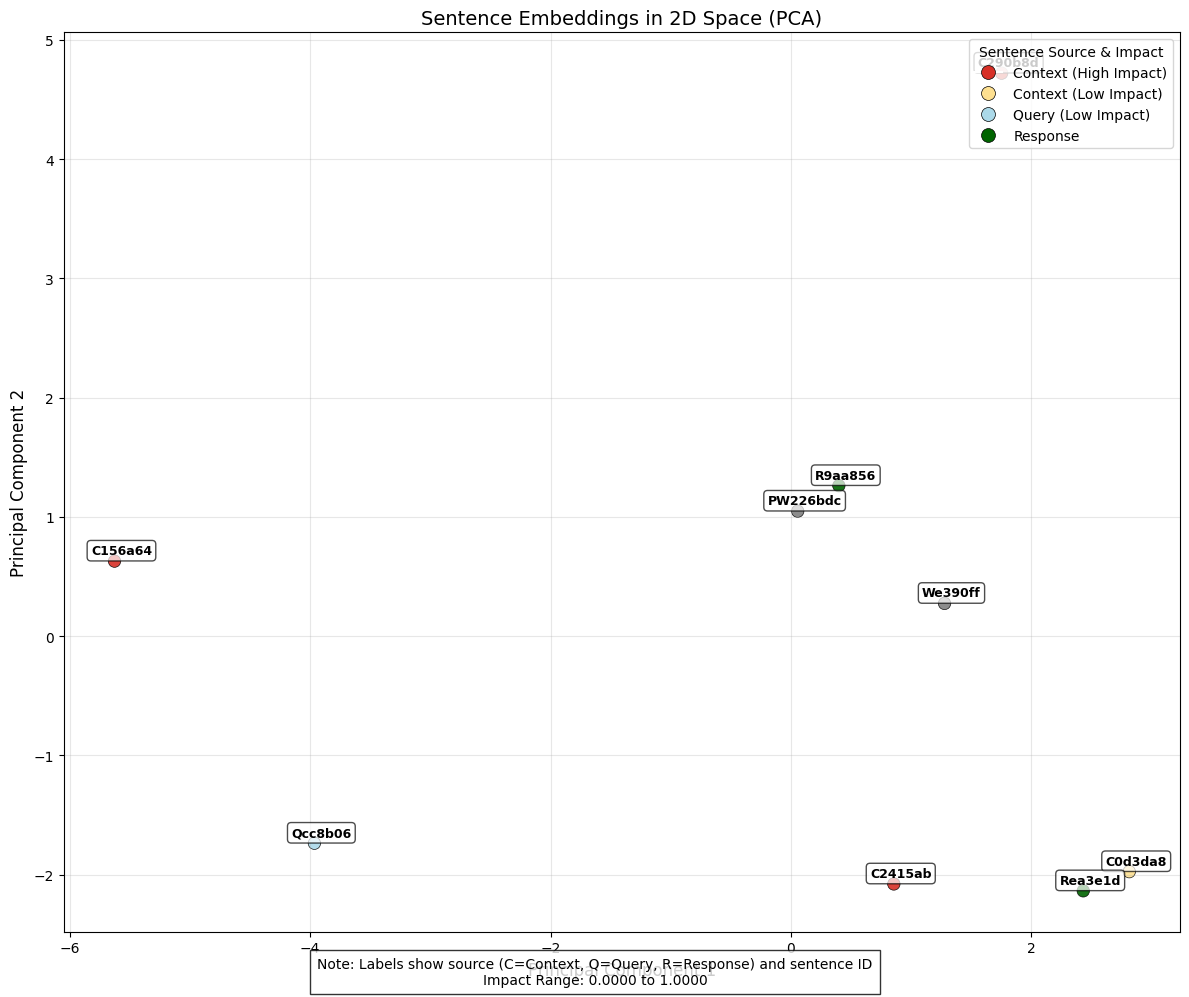

In [22]:
def plot_2d_sentence_embeddings(embeddings_2d, labels_to_plot, colors_to_plot,
                              sources_to_plot, sentence_mapping, impact_values=None):
    """Plot the 2D PCA visualization of sentence embeddings with improved colors."""
    plt.figure(figsize=(12, 10))

    # Create scatter plot with improved clarity
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1],
                         c=colors_to_plot, s=80, alpha=0.9, edgecolors='black', linewidth=0.5)

    # Add sentence labels with better positioning and improved readability
    for i, label in enumerate(labels_to_plot):
        plt.annotate(label,
                    (embeddings_2d[i, 0], embeddings_2d[i, 1]),
                    textcoords="offset points",
                    xytext=(5, 5),
                    ha='center',
                    fontsize=9,
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.7))

    # Create a better legend with colorblind-friendly colors
    legend_handles = []
    legend_labels = []

    # Group colors by source for cleaner legend
    source_colors = defaultdict(set)
    for i, source in enumerate(sources_to_plot):
        source_colors[source].add(colors_to_plot[i])

    # Context entries
    if "context" in source_colors:
        if COLORBLIND_COLORS['context_high'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_high'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (High Impact)')

        if COLORBLIND_COLORS['context_medium'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_medium'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (Medium Impact)')

        if COLORBLIND_COLORS['context_low'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_low'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (Low Impact)')

    # Query entries
    if "query" in source_colors:
        if COLORBLIND_COLORS['query_high'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_high'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (High Impact)')

        if COLORBLIND_COLORS['query_medium'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_medium'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (Medium Impact)')

        if COLORBLIND_COLORS['query_low'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_low'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (Low Impact)')

    # Response entry
    if "response" in source_colors:
        legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                       markerfacecolor=COLORBLIND_COLORS['response'],
                                       markersize=10, markeredgecolor='black', markeredgewidth=0.5))
        legend_labels.append('Response')

    # Add legend with better formatting
    plt.legend(legend_handles, legend_labels, title="Sentence Source & Impact",
              loc="upper right", frameon=True, fontsize=10)

    plt.title("Sentence Embeddings in 2D Space (PCA)", fontsize=14)
    plt.xlabel("Principal Component 1", fontsize=12)
    plt.ylabel("Principal Component 2", fontsize=12)
    plt.grid(True, alpha=0.3)

    # Add a note about sentence IDs and impact filter if applicable
    note_text = "Note: Labels show source (C=Context, Q=Query, R=Response) and sentence ID"
    if impact_values is not None:
        impact_range = f"Impact Range: {min(impact_values):.4f} to {max(impact_values):.4f}"
        note_text += f"\n{impact_range}"
    plt.figtext(0.5, 0.01, note_text, ha="center", fontsize=10,
               bbox={"facecolor":"white", "alpha":0.8, "pad":5})

    plt.tight_layout()
    plt.show()


plot_2d_sentence_embeddings(embeddings_2d, labels_to_plot, colors_to_plot,
                              sources_to_plot, sentence_mapping, impact_values)


Sentence ID Lookup Table:
------------------------------------------------------------------------------------------
ID       | Source     | Impact     | Text                                                        
------------------------------------------------------------------------------------------
C290b8d  | context    | 1.0000     | Lionel Messi won the Ballon d'Or in 2023, his eighth time...
C2415ab  | context    | 1.0000     | Cristiano Ronaldo has scored over 800 career goals and cu...
C0d3da8  | context    | 0.5000     | Erling Haaland had a record-breaking season in 2023 with ...
C156a64  | context    | 1.0000     | Football is the most popular sport in the world.            
Qcc8b06  | query      | 0.5000     | Who is the best football player in the world?               
R9aa856  | response   | 0.0000     | Many fans consider Lionel Messi to be the best football p...
Rea3e1d  | response   | 0.0000     | Others may argue for Cristiano Ronaldo or Erling Haaland ...
PW226bd

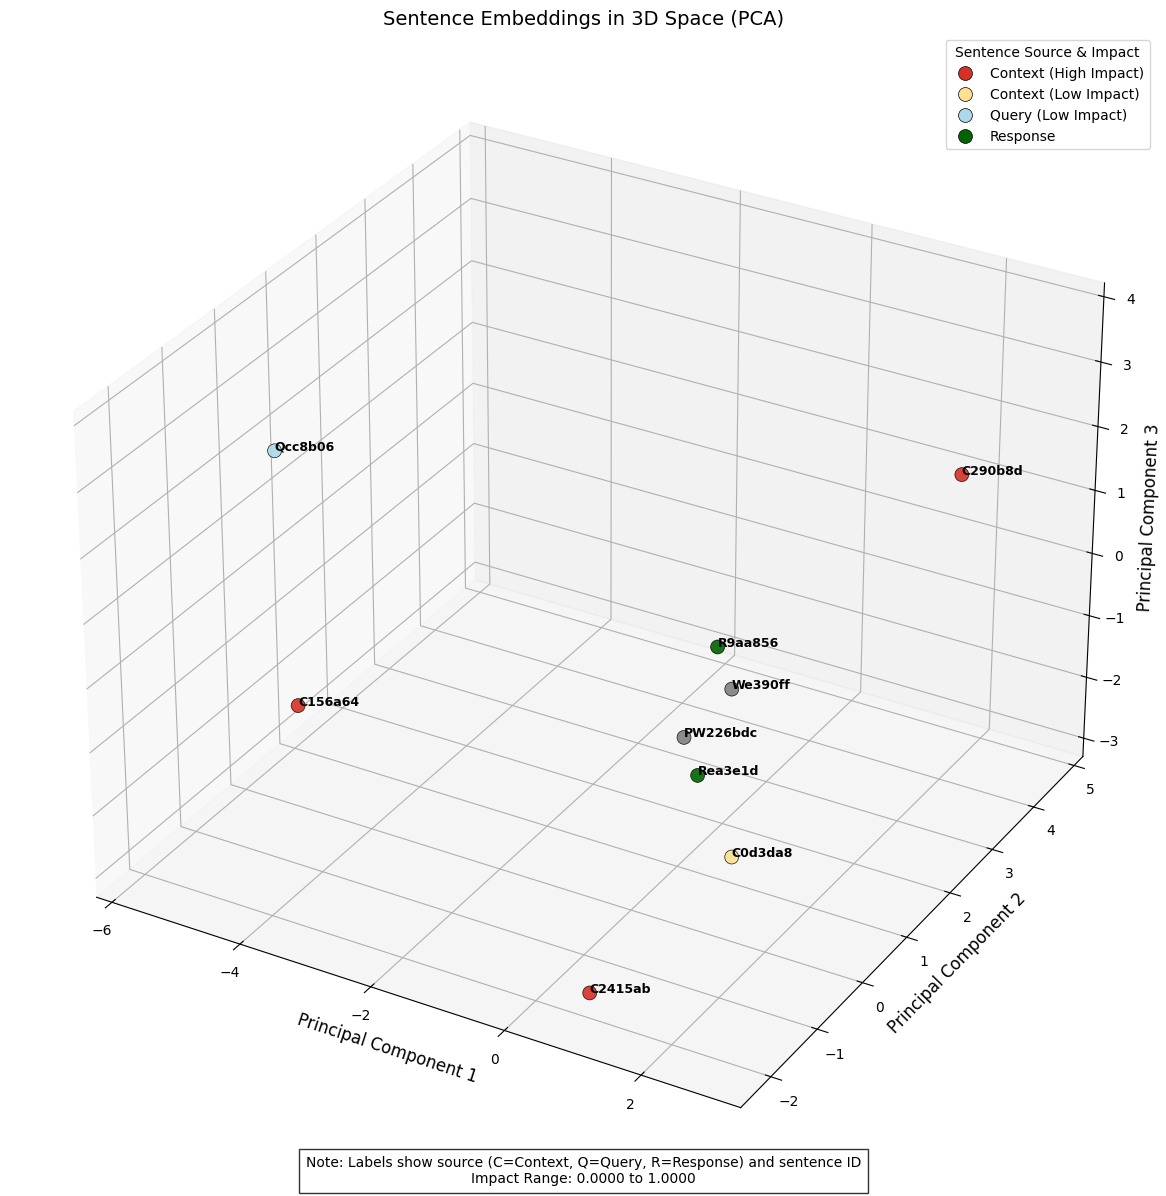

In [23]:
def plot_3d_sentence_embeddings(embeddings_3d, labels_to_plot, colors_to_plot,
                              sources_to_plot, sentence_mapping, impact_values=None):
    """Plot the 3D PCA visualization of sentence embeddings with improved colors."""
    fig_3d = plt.figure(figsize=(14, 12))
    ax_3d = fig_3d.add_subplot(111, projection='3d')

    # Create scatter plot with improved clarity
    scatter_3d = ax_3d.scatter(embeddings_3d[:, 0], embeddings_3d[:, 1], embeddings_3d[:, 2],
                              c=colors_to_plot, s=100, alpha=0.9, edgecolors='black', linewidth=0.5)

    # Add sentence labels
    for i, label in enumerate(labels_to_plot):
        ax_3d.text(embeddings_3d[i, 0], embeddings_3d[i, 1], embeddings_3d[i, 2],
                  label, fontsize=9, fontweight='bold')

    # Create a better legend with colorblind-friendly colors
    legend_handles = []
    legend_labels = []

    # Group colors by source for cleaner legend
    source_colors = defaultdict(set)
    for i, source in enumerate(sources_to_plot):
        source_colors[source].add(colors_to_plot[i])

    # Context entries
    if "context" in source_colors:
        if COLORBLIND_COLORS['context_high'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_high'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (High Impact)')

        if COLORBLIND_COLORS['context_medium'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_medium'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (Medium Impact)')

        if COLORBLIND_COLORS['context_low'] in source_colors["context"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['context_low'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Context (Low Impact)')

    # Query entries
    if "query" in source_colors:
        if COLORBLIND_COLORS['query_high'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_high'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (High Impact)')

        if COLORBLIND_COLORS['query_medium'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_medium'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (Medium Impact)')

        if COLORBLIND_COLORS['query_low'] in source_colors["query"]:
            legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                           markerfacecolor=COLORBLIND_COLORS['query_low'],
                                           markersize=10, markeredgecolor='black', markeredgewidth=0.5))
            legend_labels.append('Query (Low Impact)')

    # Response entry
    if "response" in source_colors:
        legend_handles.append(plt.Line2D([0], [0], marker='o', color='w',
                                       markerfacecolor=COLORBLIND_COLORS['response'],
                                       markersize=10, markeredgecolor='black', markeredgewidth=0.5))
        legend_labels.append('Response')

    # Add legend with better formatting
    ax_3d.legend(legend_handles, legend_labels, title="Sentence Source & Impact",
               loc="upper right", frameon=True, fontsize=10)

    ax_3d.set_title("Sentence Embeddings in 3D Space (PCA)", fontsize=14)
    ax_3d.set_xlabel("Principal Component 1", fontsize=12)
    ax_3d.set_ylabel("Principal Component 2", fontsize=12)
    ax_3d.set_zlabel("Principal Component 3", fontsize=12)

    # Add a note about sentence IDs as a text annotation below the plot
    note_text = "Note: Labels show source (C=Context, Q=Query, R=Response) and sentence ID"
    if impact_values is not None:
        impact_range = f"Impact Range: {min(impact_values):.4f} to {max(impact_values):.4f}"
        note_text += f"\n{impact_range}"
    fig_3d.text(0.5, 0.01, note_text, ha="center", fontsize=10,
               bbox={"facecolor":"white", "alpha":0.8, "pad":5})

    # Add a help function to print full sentence text when exploring
    def generate_sentence_lookup_table():
        print("\nSentence ID Lookup Table:")
        print("-" * 80)
        print(f"{'ID':<8} | {'Source':<10} | {'Text':<60}")
        print("-" * 80)
        for i, label in enumerate(labels_to_plot):
            source = sources_to_plot[i]
            text = sentence_mapping.get(label[1:], "Unknown")  # Remove the first letter (source indicator)
            print(f"{label:<8} | {source:<10} | {truncate_text(text, 60):<60}")

    # Print the lookup table with impact values
    def generate_sentence_lookup_table_with_impact():
        print("\nSentence ID Lookup Table:")
        print("-" * 90)
        print(f"{'ID':<8} | {'Source':<10} | {'Impact':<10} | {'Text':<60}")
        print("-" * 90)
        for i, label in enumerate(labels_to_plot):
            source = sources_to_plot[i]
            impact = impact_values[i] if impact_values else "N/A"
            text = sentence_mapping.get(label[1:], "Unknown")  # Remove the first letter (source indicator)
            print(f"{label:<8} | {source:<10} | {impact:<10.4f} | {truncate_text(text, 60):<60}")

    # Print the improved lookup table
    generate_sentence_lookup_table_with_impact()

    plt.tight_layout()
    plt.show()


plot_3d_sentence_embeddings(embeddings_3d, labels_to_plot, colors_to_plot,
                              sources_to_plot, sentence_mapping, impact_values)
